In [1]:
print("My Data Science Internship Project")
print("Name: Battula Jayasri Sai Tejaswini")
print("Python is working!")

My Data Science Internship Project
Name: Battula Jayasri Sai Tejaswini
Python is working!


In [2]:

# Install the dataset access package
!pip -q install ucimlrepo

# Import libraries
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Download the real UCI Online Retail dataset
online_retail = fetch_ucirepo(id=352)

# Combine the dataset columns
df = online_retail.data.original.copy()

# Display the first five rows
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

# Show column names, data types, and missing values
print("\nColumn information:")
df.info()

print("\nMissing values in each column:")
display(df.isnull().sum())


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom



Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB

Missing values in each column:


,0
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [3]:

# Make a working copy
clean_df = df.copy()

# Remove rows without a customer ID or product description
clean_df = clean_df.dropna(subset=["CustomerID", "Description"])

# Convert columns to the correct data types
clean_df["InvoiceDate"] = pd.to_datetime(clean_df["InvoiceDate"])
clean_df["CustomerID"] = clean_df["CustomerID"].astype(int)

# Remove cancelled invoices and invalid sales rows
clean_df = clean_df[
    (~clean_df["InvoiceNo"].astype(str).str.startswith("C")) &
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
].copy()

# Calculate transaction value
clean_df["Sales"] = clean_df["Quantity"] * clean_df["UnitPrice"]

# Print actual results from the cleaned dataset
print("Original rows:", len(df))
print("Rows after cleaning:", len(clean_df))
print("Unique customers:", clean_df["CustomerID"].nunique())
print("Unique invoices:", clean_df["InvoiceNo"].nunique())
print("Total sales (£):", round(clean_df["Sales"].sum(), 2))
print("Date range:", clean_df["InvoiceDate"].min(),
      "to", clean_df["InvoiceDate"].max())

display(clean_df.head())


Original rows: 541909
Rows after cleaning: 397884
Unique customers: 4338
Unique invoices: 18532
Total sales (£): 8911407.9
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Sales
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34


MONTHLY SALES


,Sales
Month,
2010-12,572713.890
2011-01,569445.040
2011-02,447137.350
2011-03,595500.760
2011-04,469200.361
2011-05,678594.560
2011-06,661213.690
2011-07,600091.011
2011-08,645343.900


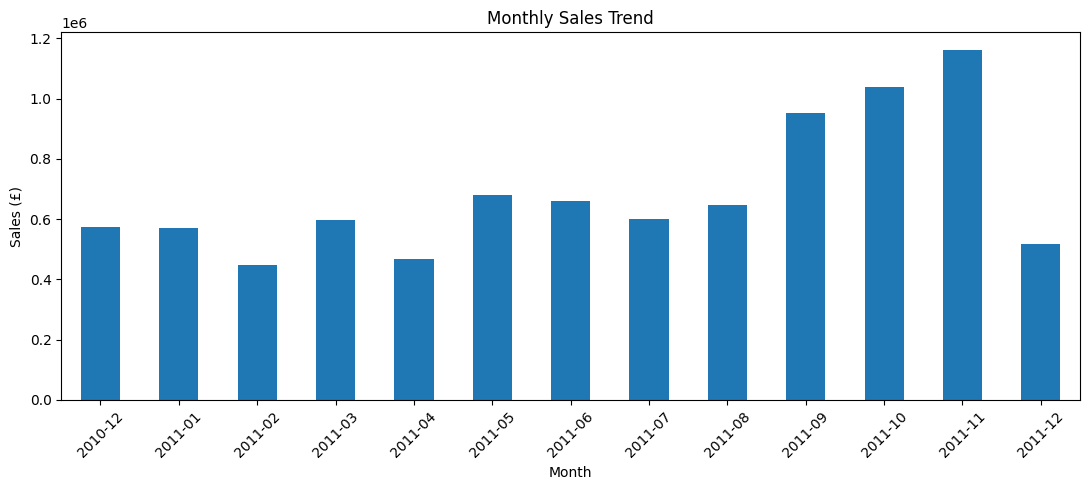

TOP 10 PRODUCTS


,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54415
JUMBO BAG RED RETROSPOT,46181
WHITE HANGING HEART T-LIGHT HOLDER,36725
ASSORTED COLOUR BIRD ORNAMENT,35362
PACK OF 72 RETROSPOT CAKE CASES,33693
POPCORN HOLDER,30931
RABBIT NIGHT LIGHT,27202


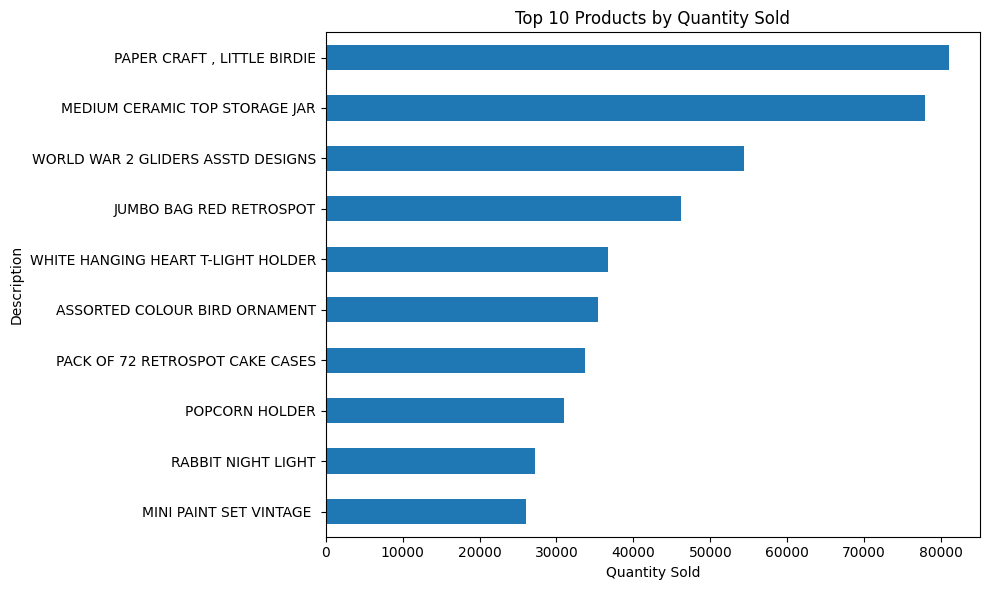

CUSTOMER RFM DATA


,CustomerID,Recency,Frequency,Monetary,RepeatPurchase
0,12346,225,1,77183.60,0
1,12347,29,5,2790.86,1
2,12348,148,3,1487.24,1
3,12350,210,1,334.40,0
4,12352,162,5,1561.81,1
5,12353,104,1,89.00,0
6,12354,132,1,1079.40,0
7,12355,114,1,459.40,0
8,12356,145,2,2753.08,1
9,12358,50,1,484.86,0



RFM DATASET SHAPE: (3317, 5)

REPEAT PURCHASE COUNTS:


,count
RepeatPurchase,
1,1864
0,1453



REPEAT PURCHASE RATE (%): 56.2


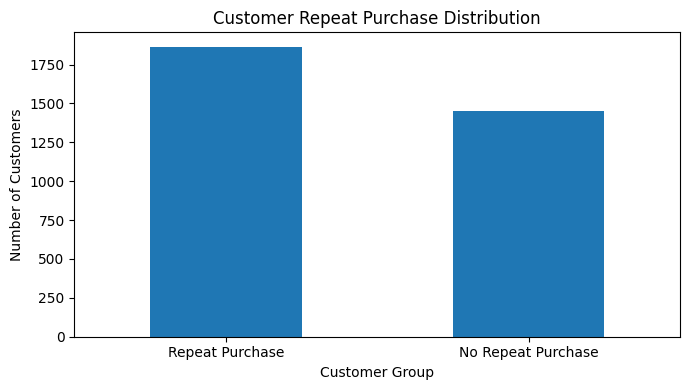

EDA AND FEATURE ENGINEERING COMPLETED!


In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# -----------------------------------
# 1. Monthly sales analysis
# -----------------------------------
clean_df["Month"] = clean_df["InvoiceDate"].dt.to_period("M")

monthly_sales = clean_df.groupby("Month")["Sales"].sum()

print("MONTHLY SALES")
display(monthly_sales)

monthly_sales.plot(kind="bar", figsize=(11, 5))
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -----------------------------------
# 2. Top 10 products by quantity
# -----------------------------------
top_products = (
    clean_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("TOP 10 PRODUCTS")
display(top_products)

top_products.sort_values().plot(kind="barh", figsize=(10, 6))
plt.title("Top 10 Products by Quantity Sold")
plt.xlabel("Quantity Sold")
plt.tight_layout()
plt.show()

# -----------------------------------
# 3. Customer-level RFM analysis
# -----------------------------------

# Prediction cutoff and 90-day future period
cutoff_date = pd.Timestamp("2011-09-01")
end_date = cutoff_date + pd.Timedelta(days=90)

# Transactions before cutoff: historical customer behaviour
history = clean_df[clean_df["InvoiceDate"] < cutoff_date].copy()

# Transactions during the next 90 days: future purchases
future = clean_df[
    (clean_df["InvoiceDate"] >= cutoff_date) &
    (clean_df["InvoiceDate"] < end_date)
].copy()

# Calculate RFM features
rfm = history.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (cutoff_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Sales", "sum")
).reset_index()

# Create repeat purchase target
future_customers = future["CustomerID"].unique()

rfm["RepeatPurchase"] = (
    rfm["CustomerID"].isin(future_customers).astype(int)
)

print("CUSTOMER RFM DATA")
display(rfm.head(10))

print("\nRFM DATASET SHAPE:", rfm.shape)
print("\nREPEAT PURCHASE COUNTS:")
display(rfm["RepeatPurchase"].value_counts())

print("\nREPEAT PURCHASE RATE (%):",
      round(rfm["RepeatPurchase"].mean() * 100, 2))

# -----------------------------------
# 4. Visualise repeat purchase behaviour
# -----------------------------------
rfm["RepeatPurchase"].value_counts().rename(
    index={0: "No Repeat Purchase", 1: "Repeat Purchase"}
).plot(kind="bar", figsize=(7, 4))

plt.title("Customer Repeat Purchase Distribution")
plt.xlabel("Customer Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

print("EDA AND FEATURE ENGINEERING COMPLETED!")


In [5]:

# ============================================
# WEEK 5: CUSTOMER REPEAT PURCHASE PREDICTION
# ============================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

# Select input features and prediction target
X = rfm[["Recency", "Frequency", "Monetary"]]
y = rfm["RepeatPurchase"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# --------------------------------------------
# Model 1: Logistic Regression
# --------------------------------------------
log_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

log_model.fit(X_train, y_train)

log_predictions = log_model.predict(X_test)
log_probabilities = log_model.predict_proba(X_test)[:, 1]

# --------------------------------------------
# Model 2: Random Forest
# --------------------------------------------
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    min_samples_leaf=5,
    random_state=42,
    class_weight="balanced"
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)
rf_probabilities = rf_model.predict_proba(X_test)[:, 1]

# --------------------------------------------
# Evaluate both models
# --------------------------------------------
def evaluate_model(name, actual, predicted, probabilities):
    print("\n" + "=" * 45)
    print(name)
    print("=" * 45)

    print("Accuracy:", round(accuracy_score(actual, predicted), 4))
    print("Precision:", round(precision_score(actual, predicted, zero_division=0), 4))
    print("Recall:", round(recall_score(actual, predicted, zero_division=0), 4))
    print("F1 Score:", round(f1_score(actual, predicted, zero_division=0), 4))
    print("ROC-AUC:", round(roc_auc_score(actual, probabilities), 4))

    print("\nClassification Report:")
    print(classification_report(actual, predicted, zero_division=0))

    print("Confusion Matrix:")
    print(confusion_matrix(actual, predicted))

evaluate_model(
    "LOGISTIC REGRESSION",
    y_test, log_predictions, log_probabilities
)

evaluate_model(
    "RANDOM FOREST",
    y_test, rf_predictions, rf_probabilities
)

# --------------------------------------------
# Compare model performance
# --------------------------------------------
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [
        accuracy_score(y_test, log_predictions),
        accuracy_score(y_test, rf_predictions)
    ],
    "Precision": [
        precision_score(y_test, log_predictions, zero_division=0),
        precision_score(y_test, rf_predictions, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, log_predictions, zero_division=0),
        recall_score(y_test, rf_predictions, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, log_predictions, zero_division=0),
        f1_score(y_test, rf_predictions, zero_division=0)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, log_probabilities),
        roc_auc_score(y_test, rf_probabilities)
    ]
})

print("\nMODEL COMPARISON")
display(results.round(4))

# Save results for Week 6
results.to_csv("model_comparison.csv", index=False)

print("Week 5 modelling completed!")


Training records: 2653
Testing records: 664

LOGISTIC REGRESSION
Accuracy: 0.6521
Precision: 0.6909
Recall: 0.689
F1 Score: 0.6899
ROC-AUC: 0.7156

Classification Report:
              precision    recall  f1-score   support

           0       0.60      0.60      0.60       291
           1       0.69      0.69      0.69       373

    accuracy                           0.65       664
   macro avg       0.65      0.65      0.65       664
weighted avg       0.65      0.65      0.65       664

Confusion Matrix:
[[176 115]
 [116 257]]

RANDOM FOREST
Accuracy: 0.6566
Precision: 0.7346
Recall: 0.6086
F1 Score: 0.6657
ROC-AUC: 0.7265

Classification Report:
              precision    recall  f1-score   support

           0       0.59      0.72      0.65       291
           1       0.73      0.61      0.67       373

    accuracy                           0.66       664
   macro avg       0.66      0.66      0.66       664
weighted avg       0.67      0.66      0.66       664

Confusion Ma

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6521,0.6909,0.6890,0.6899,0.7156
1,Random Forest,0.6566,0.7346,0.6086,0.6657,0.7265


Week 5 modelling completed!


SELECTED MODEL: Logistic Regression

FEATURE IMPORTANCE


,Importance
Frequency,1.801260
Recency,0.348242
Monetary,0.008124


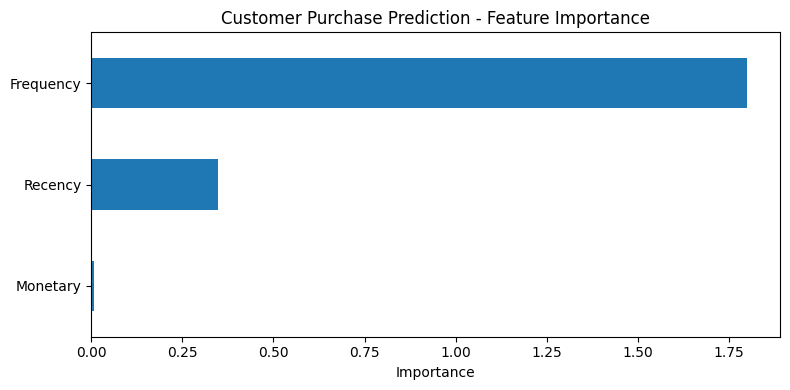

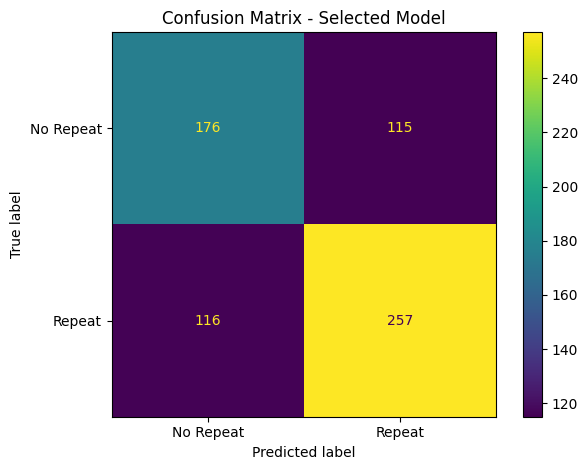

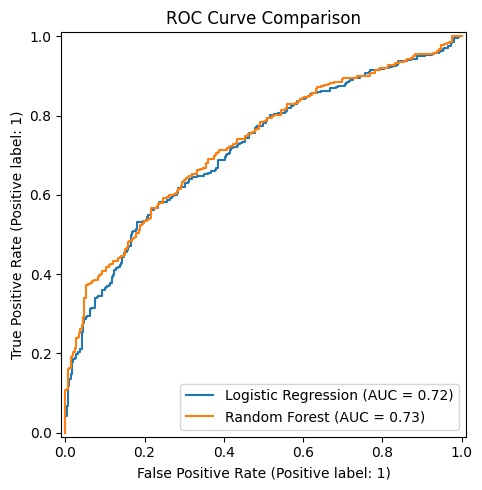


FINAL PROJECT SUMMARY


,Item,Result
0,Original dataset rows,541909
1,Cleaned dataset rows,397884
2,Unique customers in cleaned dataset,4338
3,Customers in prediction cohort,3317
4,Repeat purchasers in cohort,1864
5,Non-repeat purchasers in cohort,1453
6,Repeat purchase rate (%),56.2
7,Selected model,Logistic Regression
8,Test records,664
9,Logistic Regression accuracy,0.6521



WEEK 6 EVALUATION COMPLETED!
Files saved successfully.


In [6]:

# ============================================
# WEEK 6: FINAL EVALUATION AND REPORTING
# ============================================

import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay

# 1. Select the model based on F1-score
best_model_name = (
    "Logistic Regression"
    if f1_score(y_test, log_predictions) >=
       f1_score(y_test, rf_predictions)
    else "Random Forest"
)

best_model = (
    log_model if best_model_name == "Logistic Regression"
    else rf_model
)

print("SELECTED MODEL:", best_model_name)

# 2. Display feature importance
if best_model_name == "Logistic Regression":
    importance = pd.Series(
        abs(log_model.named_steps["classifier"].coef_[0]),
        index=X.columns
    )
else:
    importance = pd.Series(
        rf_model.feature_importances_,
        index=X.columns
    )

importance = importance.sort_values(ascending=False)

print("\nFEATURE IMPORTANCE")
display(importance.to_frame("Importance"))

importance.sort_values().plot(
    kind="barh", figsize=(8, 4)
)
plt.title("Customer Purchase Prediction - Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

# 3. Confusion matrix for selected model
best_predictions = best_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions,
    display_labels=["No Repeat", "Repeat"]
)
plt.title("Confusion Matrix - Selected Model")
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

# 4. ROC curve for both models
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_estimator(
    log_model, X_test, y_test,
    name="Logistic Regression", ax=ax
)

RocCurveDisplay.from_estimator(
    rf_model, X_test, y_test,
    name="Random Forest", ax=ax
)

plt.title("ROC Curve Comparison")
plt.tight_layout()
plt.savefig("roc_curve.png", dpi=150)
plt.show()

# 5. Save model comparison
results.to_csv("model_comparison.csv", index=False)

# 6. Save the selected model
joblib.dump(best_model, "best_repeat_purchase_model.pkl")

# 7. Save evaluation summary
summary = pd.DataFrame({
    "Item": [
        "Original dataset rows",
        "Cleaned dataset rows",
        "Unique customers in cleaned dataset",
        "Customers in prediction cohort",
        "Repeat purchasers in cohort",
        "Non-repeat purchasers in cohort",
        "Repeat purchase rate (%)",
        "Selected model",
        "Test records",
        "Logistic Regression accuracy",
        "Random Forest accuracy"
    ],
    "Result": [
        len(df),
        len(clean_df),
        clean_df["CustomerID"].nunique(),
        len(rfm),
        int(rfm["RepeatPurchase"].sum()),
        int((rfm["RepeatPurchase"] == 0).sum()),
        round(rfm["RepeatPurchase"].mean() * 100, 2),
        best_model_name,
        len(y_test),
        round(accuracy_score(y_test, log_predictions), 4),
        round(accuracy_score(y_test, rf_predictions), 4)
    ]
})

print("\nFINAL PROJECT SUMMARY")
display(summary)

summary.to_csv("final_project_summary.csv", index=False)

print("\nWEEK 6 EVALUATION COMPLETED!")
print("Files saved successfully.")


In [7]:

import zipfile
import os

files_to_save = [
    "model_comparison.csv",
    "final_project_summary.csv",
    "feature_importance.png",
    "confusion_matrix.png",
    "roc_curve.png",
    "best_repeat_purchase_model.pkl"
]

with zipfile.ZipFile(
    "Jayasri_Sai_Tejaswini_Project_Results.zip", "w"
) as zip_file:

    for file in files_to_save:
        if os.path.exists(file):
            zip_file.write(file)

print("Project results ZIP created successfully!")

from google.colab import files
files.download("Jayasri_Sai_Tejaswini_Project_Results.zip")


Project results ZIP created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>